# 06 — Transferencia leave-one-asset-out de correctores TSMOM

> Cada ETF queda reservado una vez. Para cada experimento, las escalas, el calendario de entrenamiento y los gradientes usan exclusivamente los otros seis ETFs. El resultado es exploratorio: los activos fueron seleccionados previamente, están correlacionados y ya conocemos resultados de XLE y XLF.

## <b>Block 01 — Panel Gold, baseline y aislamiento</b>

> El baseline usa momentum logarítmico 126d, EWMA $\lambda=0.94$, objetivo de volatilidad 12% y tope 1×. La decisión de $t$ se aplica al retorno de $t+1$. Cada calendario de entrenamiento se forma antes de consultar la serie del ETF reservado.

In [1]:
from pathlib import Path
import math, random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from torch import nn
torch.set_num_threads(1)

SEED, EPOCHS, LEARNING_RATE = 42, 80, 0.01
START, LOOKBACK = pd.Timestamp('2018-01-02'), 63
FEATURES = ['ret_1d', 'mom_21', 'mom_63', 'mom_126', 'ewma_vol_annual']
LAMBDA, WARMUP, TARGET, MAX_EXPOSURE, LIMIT, COST = .94, 20, .12, 1., .20, .0005
ASSETS = ['SPY','QQQ','IWM','IWD','IWF','XLE','XLF']
CYCLES = [('2024',pd.Timestamp('2023-12-31'),pd.Timestamp('2024-01-01'),pd.Timestamp('2024-12-31')),('2025',pd.Timestamp('2024-12-31'),pd.Timestamp('2025-01-01'),pd.Timestamp('2025-12-31')),('2026',pd.Timestamp('2025-12-31'),pd.Timestamp('2026-01-01'),None)]

def root(start=Path.cwd()):
    for p in (start.resolve(), *start.resolve().parents):
        if (p/'Momentum_systematic_strategies').is_dir(): return p
    raise FileNotFoundError('No se encontró la raíz del repositorio.')

GOLD=root()/'Momentum_systematic_strategies'/'data'/'gold'/'daily_series'/'etf'
def make_sample(symbol):
    raw=pl.read_parquet(GOLD/(symbol+'.parquet')).select('session_date','adjusted_close').sort('session_date')
    f=pd.DataFrame(raw.filter(pl.col('session_date')>=START.date()).to_dict(as_series=False)).rename(columns={'session_date':'decision_date'})
    f['decision_date']=pd.to_datetime(f['decision_date']); f['ret_1d']=f.adjusted_close.pct_change()
    for h in (21,63,126): f['mom_{}'.format(h)]=np.log(f.adjusted_close/f.adjusted_close.shift(h))
    r=f.ret_1d.to_numpy(float); v=np.full(len(f),np.nan); first=np.flatnonzero(np.isfinite(r))[0]; init=first+WARMUP-1; v[init]=np.mean(r[first:init+1]**2)
    for i in range(init+1,len(f)): v[i]=LAMBDA*v[i-1]+(1-LAMBDA)*r[i]**2
    f['ewma_vol_annual']=np.sqrt(v)*math.sqrt(252); f['vol_cap']=np.minimum(MAX_EXPOSURE,TARGET/f.ewma_vol_annual)
    f['baseline']=np.where(f.mom_126>0,f.vol_cap,0.); f['return_date'],f['next_return']=f.decision_date.shift(-1),f.ret_1d.shift(-1)
    f['ready']=f[FEATURES].notna().all(axis=1).astype(int).rolling(LOOKBACK).sum().eq(LOOKBACK); f['_row']=np.arange(len(f))
    return f, f.loc[f.ready & f.next_return.notna()].copy().reset_index(drop=True)

frames,sample_list=zip(*[make_sample(s) for s in ASSETS]); frames=dict(zip(ASSETS,frames)); raw_samples=dict(zip(ASSETS,sample_list))
print('Gold local disponible para siete ETFs desde 2018; la inferencia usa solamente indicadores históricos de cada activo.')

Gold local disponible para siete ETFs desde 2018; la inferencia usa solamente indicadores históricos de cada activo.


## <b>Block 02 — Redes compartidas y pérdida temporal</b>

> Cada red aprende una corrección residual acotada a $\pm0.20$. Los retornos netos se calculan por ETF y se promedian por fecha con igual peso antes de calcular Sharpe; no se concatenan pares activo-fecha como observaciones temporales independientes.

In [2]:
class SharedFF(nn.Module):
    def __init__(self):
        super().__init__(); self.hidden=nn.Linear(5,8); self.out=nn.Linear(8,1); nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)
    def forward(self,x): return LIMIT*torch.tanh(self.out(torch.tanh(self.hidden(x)))).squeeze(-1)

class SharedLSTM(nn.Module):
    def __init__(self):
        super().__init__(); self.lstm=nn.LSTM(5,8,batch_first=True); self.out=nn.Linear(8,1); nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)
    def forward(self,x): return LIMIT*torch.tanh(self.out(self.lstm(x)[0][:,-1])).squeeze(-1)

def residual(model,x):
    a,t=x.shape[:2]; return model(x.reshape(a*t,*x.shape[2:])).reshape(a,t)

def fit(model,x,base,returns,train_idx):
    optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE); index=torch.tensor(train_idx,dtype=torch.long)
    for _ in range(EPOCHS):
        optimizer.zero_grad(); position=torch.clamp(base[:,index]+residual(model,x[:,index]),0,1)
        turnover=torch.abs(position[:,1:]-position[:,:-1]); net=position[:,1:]*returns[:,index][:,1:]-COST*turnover
        portfolio=net.mean(0); loss=-(portfolio.mean()/portfolio.std(unbiased=False).clamp_min(1e-6)*math.sqrt(252))
        loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
    return model

pd.DataFrame({'modelo':['TSMOM','Feedforward compartido','LSTM compartida'],'parámetros entrenables':[0,sum(p.numel() for p in SharedFF().parameters()),sum(p.numel() for p in SharedLSTM().parameters())]})

,modelo,parámetros entrenables
0,TSMOM,0
1,Feedforward compartido,57
2,LSTM compartida,489


## <b>Block 03 — Walk-forward leave-one-asset-out</b>

> Cada ciclo reentrena desde cero hasta el cierre del año anterior. La posición heredada cubre la sesión puente; la primera posición del modelo nuevo solo entra después de estar disponible. La versión limitada recorta la posición de la red al techo causal $\min(1,0.12/\hat\sigma_t)$ y recalcula todo el turnover.

In [3]:
def experiment(held):
    train_assets=[s for s in ASSETS if s!=held]
    train_dates=set.intersection(*(set(raw_samples[s].decision_date) for s in train_assets))
    excluded_by_held=len(train_dates-set(raw_samples[held].decision_date))
    train_samples={s:raw_samples[s].loc[raw_samples[s].decision_date.isin(train_dates)].copy().reset_index(drop=True) for s in train_assets}
    eval_end=min(train_samples[s].return_date.max() for s in train_assets)
    held_sample=raw_samples[held].loc[raw_samples[held].return_date<=eval_end].copy().reset_index(drop=True)
    assert all(np.array_equal(train_samples[s].decision_date.to_numpy(),train_samples[train_assets[0]].decision_date.to_numpy()) for s in train_assets)
    def tensors(train_end):
        train_idx=np.flatnonzero((train_samples[train_assets[0]].return_date<=train_end).to_numpy())
        raw_train=np.concatenate([frames[s].loc[train_samples[s]._row.to_numpy(),FEATURES].to_numpy(np.float32)[train_idx] for s in train_assets])
        mean,std=raw_train.mean(0),np.maximum(raw_train.std(0),1e-8)
        seq,current,base,returns=[],[],[],[]
        for s in train_assets:
            full=(frames[s][FEATURES].to_numpy(np.float32)-mean)/std; rows=train_samples[s]._row.to_numpy(); current.append(full[rows]); seq.append(np.stack([full[i-LOOKBACK+1:i+1] for i in rows])); base.append(train_samples[s].baseline.to_numpy(np.float32)); returns.append(train_samples[s].next_return.to_numpy(np.float32))
        full=(frames[held][FEATURES].to_numpy(np.float32)-mean)/std; rows=held_sample._row.to_numpy(); held_seq=np.stack([full[i-LOOKBACK+1:i+1] for i in rows]); held_current=full[rows]
        return train_idx,torch.tensor(np.stack(seq)),torch.tensor(np.stack(current)),torch.tensor(np.stack(base)),torch.tensor(np.stack(returns)),torch.tensor(held_seq[None]),torch.tensor(held_current[None])
    labels=['TSMOM','Feedforward','LSTM','Feedforward limitada','LSTM limitada']; previous={k:0. for k in labels}; records=[]; schedule=[]
    for cycle,train_end,start,end in CYCLES:
        end=eval_end if end is None else min(end,eval_end); train_idx,xseq,xcur,base,returns,hseq,hcur=tensors(train_end)
        available=train_samples[train_assets[0]].loc[train_idx,'return_date'].max(); target=np.flatnonzero(((held_sample.return_date>=start)&(held_sample.return_date<=end)).to_numpy()); active=target[held_sample.loc[target,'decision_date'].to_numpy()>available]; bridge=target[held_sample.loc[target,'decision_date'].to_numpy()<=available]
        assert len(target)==len(active)+len(bridge) and len(active)>0 and held_sample.loc[active,'decision_date'].min()>available
        np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED); lstm=fit(SharedLSTM(),xseq,base,returns,train_idx); ff=fit(SharedFF(),xcur,base,returns,train_idx)
        with torch.no_grad():
            base_h=held_sample.baseline.to_numpy(np.float32); ff_h=np.clip(base_h+residual(ff,hcur).numpy().ravel(),0,1); lstm_h=np.clip(base_h+residual(lstm,hseq).numpy().ravel(),0,1); cap_h=held_sample.vol_cap.to_numpy(np.float32)
        policies={'TSMOM':base_h,'Feedforward':ff_h,'LSTM':lstm_h,'Feedforward limitada':np.minimum(ff_h,cap_h),'LSTM limitada':np.minimum(lstm_h,cap_h)}
        for label,position in policies.items():
            if len(bridge):
                ret=held_sample.loc[bridge,'next_return'].to_numpy(); records.append(pd.DataFrame({'activo':held,'ciclo':cycle,'return_date':held_sample.loc[bridge,'return_date'].to_numpy(),'estrategia':label,'position':previous[label],'gross':previous[label]*ret,'costs':0.,'net':previous[label]*ret,'turnover':0.,'vol_cap':np.nan}))
            w=position[active]; turn=np.r_[abs(w[0]-previous[label]),abs(np.diff(w))]; ret=held_sample.loc[active,'next_return'].to_numpy(); records.append(pd.DataFrame({'activo':held,'ciclo':cycle,'return_date':held_sample.loc[active,'return_date'].to_numpy(),'estrategia':label,'position':w,'gross':w*ret,'costs':COST*turn,'net':w*ret-COST*turn,'turnover':turn,'vol_cap':held_sample.loc[active,'vol_cap'].to_numpy()})); previous[label]=w[-1]
        schedule.append({'activo reservado':held,'ciclo':cycle,'modelo disponible tras':available.date(),'primera decisión':held_sample.loc[active,'decision_date'].min().date(),'sesiones puente':len(bridge),'retornos':len(target)})
    daily=pd.concat(records).sort_values(['estrategia','return_date']).reset_index(drop=True); expected=held_sample.loc[(held_sample.return_date>=pd.Timestamp('2024-01-01'))&(held_sample.return_date<=eval_end),'return_date'].to_numpy()
    assert all(np.array_equal(p.return_date.to_numpy(),expected) for _,p in daily.groupby('estrategia')) and np.allclose(daily.net,daily.gross-daily.costs)
    limited=daily.loc[daily.estrategia.str.contains('limitada')]; assert daily.position.between(0,1).all() and np.all(limited.loc[limited.vol_cap.notna(),'position']<=limited.loc[limited.vol_cap.notna(),'vol_cap']+1e-7)
    calendar={'activo reservado':held,'ETFs entrenamiento':', '.join(train_assets),'decisiones entrenamiento':len(train_dates),'excluidas por reservado':excluded_by_held,'fin evaluación':eval_end.date(),'sesiones evaluación':len(expected)}
    return daily,pd.DataFrame(schedule),calendar

all_daily=[]; all_schedule=[]; calendars=[]
for held in ASSETS:
    daily,schedule,calendar=experiment(held); all_daily.append(daily); all_schedule.append(schedule); calendars.append(calendar)
daily=pd.concat(all_daily).reset_index(drop=True); schedule=pd.concat(all_schedule).reset_index(drop=True); calendar_report=pd.DataFrame(calendars)
assert calendar_report['sesiones evaluación'].eq(723).all(); calendar_report

,activo reservado,ETFs entrenamiento,decisiones entrenamiento,excluidas por reservado,fin evaluación,sesiones evaluación
0,SPY,"QQQ, IWM, IWD, IWF, XLE, XLF",2043,0,2026-11-17,723
1,QQQ,"SPY, IWM, IWD, IWF, XLE, XLF",2043,0,2026-11-17,723
2,IWM,"SPY, QQQ, IWD, IWF, XLE, XLF",2043,0,2026-11-17,723
3,IWD,"SPY, QQQ, IWM, IWF, XLE, XLF",2043,0,2026-11-17,723
4,IWF,"SPY, QQQ, IWM, IWD, XLE, XLF",2043,0,2026-11-17,723
5,XLE,"SPY, QQQ, IWM, IWD, IWF, XLF",2043,0,2026-11-17,723
6,XLF,"SPY, QQQ, IWM, IWD, IWF, XLE",2043,0,2026-11-17,723


## <b>Block 04 — Resultados de transferencia</b>

> Las tres políticas originales se comparan en las mismas fechas de cada ETF reservado. Las políticas limitadas son un diagnóstico secundario: comparten el techo causal de volatilidad, pero ese techo no implica igual volatilidad realizada.

,activo,estrategia,retorno neto compuesto (%),Sharpe neto,volatilidad anual (%),max drawdown (%),exposición media (%),turnover total,costes totales (%)
0,SPY,Feedforward,41.319,1.056,12.117,-9.709,90.875,14.223,0.711
2,SPY,LSTM,27.446,0.979,9.052,-6.661,69.404,19.066,0.953
4,SPY,TSMOM,30.581,0.892,11.125,-8.651,83.591,18.062,0.903
5,QQQ,Feedforward,42.357,0.896,15.010,-12.192,80.497,26.440,1.322
7,QQQ,LSTM,21.223,0.649,11.320,-9.708,59.615,23.884,1.194
9,QQQ,TSMOM,28.664,0.800,11.858,-9.234,63.540,18.991,0.950
10,IWM,Feedforward,9.802,0.299,14.357,-13.676,70.838,36.878,1.844
12,IWM,LSTM,3.290,0.154,11.852,-11.832,58.589,35.536,1.777
14,IWM,TSMOM,3.857,0.174,11.140,-10.895,52.900,27.375,1.369
15,IWD,Feedforward,55.544,1.437,11.153,-9.908,93.714,5.825,0.291


,activo,estrategia,Δ exposición media (pp),Δ bruto suma (%),Δ costes suma (pp),Δ neto suma (%),Δ neto diario (bps)
0,SPY,Feedforward,7.284,8.046,-0.192,8.238,1.139
1,SPY,LSTM,-14.187,-2.983,0.050,-3.034,-0.420
2,QQQ,Feedforward,16.956,11.710,0.372,11.337,1.568
3,QQQ,LSTM,-3.925,-5.895,0.245,-6.139,-0.849
4,IWM,Feedforward,17.939,7.219,0.475,6.744,0.933
5,IWM,LSTM,5.689,0.097,0.408,-0.311,-0.043
6,IWD,Feedforward,3.930,4.704,-0.192,4.896,0.677
7,IWD,LSTM,-15.501,-5.953,0.007,-5.960,-0.824
8,IWF,Feedforward,16.419,9.894,0.197,9.697,1.341
9,IWF,LSTM,4.607,10.089,-0.086,10.175,1.407


,estrategia,activos,media_Δ_neto_bps,mediana_Δ_neto_bps,mínimo_Δ_neto_bps,máximo_Δ_neto_bps
0,Feedforward,7,1.175,1.139,0.677,1.568
1,LSTM,7,-0.120,-0.420,-0.849,1.407


,activo,estrategia,retorno neto compuesto (%) original,retorno neto compuesto (%) limitada,volatilidad anual (%) original,volatilidad anual (%) limitada,turnover total original,turnover total limitada,costes totales (%) original,costes totales (%) limitada,Δ retorno por límite (pp)
0,SPY,Feedforward,41.319,35.597,12.117,11.277,14.223,16.294,0.711,0.815,-5.722
1,SPY,LSTM,27.446,27.582,9.052,9.000,19.066,16.972,0.953,0.849,0.136
2,QQQ,Feedforward,42.357,31.717,15.010,12.054,26.440,20.426,1.322,1.021,-10.640
3,QQQ,LSTM,21.223,21.685,11.320,10.146,23.884,20.122,1.194,1.006,0.462
4,IWM,Feedforward,9.802,8.828,14.357,11.343,36.878,26.324,1.844,1.316,-0.974
5,IWM,LSTM,3.290,3.612,11.852,10.146,35.536,28.271,1.777,1.414,0.323
6,IWD,Feedforward,55.544,51.074,11.153,10.772,5.825,9.419,0.291,0.471,-4.470
7,IWD,LSTM,40.531,39.841,8.696,8.677,9.791,9.810,0.490,0.491,-0.691
8,IWF,Feedforward,25.290,19.547,14.323,11.803,33.407,27.084,1.670,1.354,-5.743
9,IWF,LSTM,26.692,19.708,12.693,10.859,27.748,26.491,1.387,1.325,-6.984


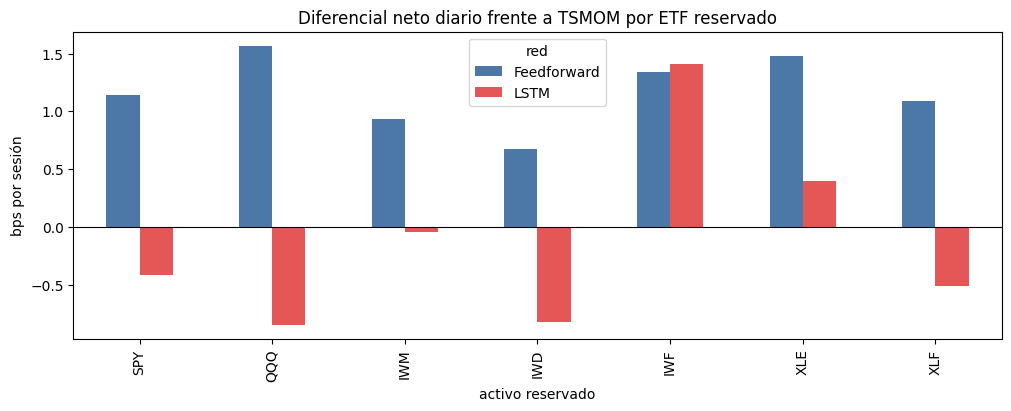

In [4]:
def metrics(part):
    net=part.net.to_numpy(); nav=np.r_[1.,np.cumprod(1+net)]; sd=net.std(ddof=0)
    return pd.Series({'retorno neto compuesto (%)':(nav[-1]-1)*100,'Sharpe neto':net.mean()/max(sd,1e-8)*math.sqrt(252),'volatilidad anual (%)':sd*math.sqrt(252)*100,'max drawdown (%)':(nav/np.maximum.accumulate(nav)-1).min()*100,'exposición media (%)':part.position.mean()*100,'turnover total':part.turnover.sum(),'costes totales (%)':part.costs.sum()*100})

original=['TSMOM','Feedforward','LSTM']; limited=['Feedforward limitada','LSTM limitada']
summary=daily.groupby(['activo','estrategia'],sort=False).apply(metrics,include_groups=False).reset_index(); main=summary.loc[summary.estrategia.isin(original)].copy()
deltas=[]
for asset in ASSETS:
    base=daily.loc[(daily.activo==asset)&(daily.estrategia=='TSMOM')].set_index('return_date')
    for label in ['Feedforward','LSTM']:
        p=daily.loc[(daily.activo==asset)&(daily.estrategia==label)].set_index('return_date'); delta=p[['position','gross','costs','net']]-base[['position','gross','costs','net']]
        assert np.allclose(delta.net,delta.gross-delta.costs)
        deltas.append({'activo':asset,'estrategia':label,'Δ exposición media (pp)':delta.position.mean()*100,'Δ bruto suma (%)':delta.gross.sum()*100,'Δ costes suma (pp)':delta.costs.sum()*100,'Δ neto suma (%)':delta.net.sum()*100,'Δ neto diario (bps)':delta.net.mean()*1e4})
delta_table=pd.DataFrame(deltas); transversal=delta_table.groupby('estrategia').agg(activos=('activo','size'),media_Δ_neto_bps=('Δ neto diario (bps)','mean'),mediana_Δ_neto_bps=('Δ neto diario (bps)','median'),mínimo_Δ_neto_bps=('Δ neto diario (bps)','min'),máximo_Δ_neto_bps=('Δ neto diario (bps)','max')).reset_index()
cap_compare=summary.loc[summary.estrategia.isin(['Feedforward','LSTM'])].merge(summary.loc[summary.estrategia.isin(limited)].assign(modelo=lambda x:x.estrategia.str.replace(' limitada',''))[['activo','modelo','retorno neto compuesto (%)','volatilidad anual (%)','turnover total','costes totales (%)']],left_on=['activo','estrategia'],right_on=['activo','modelo'],suffixes=(' original',' limitada'))
cap_compare['Δ retorno por límite (pp)']=cap_compare['retorno neto compuesto (%) limitada']-cap_compare['retorno neto compuesto (%) original']
display(main.round(3)); display(delta_table.round(3)); display(transversal.round(3)); display(cap_compare[['activo','estrategia','retorno neto compuesto (%) original','retorno neto compuesto (%) limitada','volatilidad anual (%) original','volatilidad anual (%) limitada','turnover total original','turnover total limitada','costes totales (%) original','costes totales (%) limitada','Δ retorno por límite (pp)']].round(3))

plot=delta_table.pivot(index='activo',columns='estrategia',values='Δ neto diario (bps)').reindex(ASSETS); fig,ax=plt.subplots(figsize=(10,4),layout='constrained'); plot.plot.bar(ax=ax,color=['#4c78a8','#e45756']); ax.axhline(0,color='black',lw=.8); ax.set_title('Diferencial neto diario frente a TSMOM por ETF reservado'); ax.set_ylabel('bps por sesión'); ax.set_xlabel('activo reservado'); ax.legend(title='red'); plt.show()

## <b>Conclusión</b>

- Cada ETF fue reservado de forma completa de su calendario, normalización y gradientes; las comparaciones se hacen sobre las mismas sesiones por ETF.
- En esta realización, la feedforward tiene diferencial neto diario positivo frente a TSMOM en los siete ETFs; la LSTM es heterogénea y su diferencial transversal medio es ligeramente negativo.
- Limitar la exposición al techo causal cambia los resultados de forma desigual: reduce la mayoría de los retornos de la feedforward y tiene efectos mixtos en la LSTM.
- Los diferenciales frente a TSMOM separan exposición, retorno bruto y costes para distinguir timing de simple mayor inversión.
- El diagnóstico de posiciones limitadas aclara la sensibilidad al techo de volatilidad causal, pero no iguala automáticamente la volatilidad realizada.
- Las siete transferencias no son observaciones independientes: hay correlación económica entre ETFs, selección previa de activos y conocimiento de resultados anteriores. Ningún ganador se selecciona aquí.